1-FIND UNMATCHED ZONES IN TRIOS.CSV , ZONES.CSV AND FIX THE ISSUE BY MAPPING LEGACY pickup-zone NAMES TO CURRENT ZONE NAMES

In [ ]:
import pandas as pd

trips=pd.read_csv("CairoGo_pack_v00/trips.csv")
zones=pd.read_csv("CairoGo_pack_v00/zones.csv")


unmatched = set(trips["pickup_zone"])- set(zones["zone_name"])

unmatched_Count=trips["pickup_zone"].isin(unmatched).sum()
unmatched_Fraction= unmatched_Count / len(trips)



print("unmatched Zones : " , unmatched)
print("unmatched rows : " , unmatched_Count)
print("unmatched fraction : " , unmatched_Fraction)



unmatched Zones :  {'Badr City', 'Agouza'}
unmatched rows :  2455
unmatched fraction :  0.09031712162460452


In [ ]:
results = {}

results["join"] = {
    "unmatched_before": 0.09031712162460452,
    "unmatched_zones": ["Agouza", "Badr City"],
    "fix": "Mapped legacy pickup-zone names to current zone names using zones.csv"
}

In [ ]:
zone_mapping = dict(
    zip(zones["legacy_name"], zones["zone_name"])
)

trips["pickup_zone"] = (
    trips["pickup_zone"].replace(zone_mapping)
)

remaining=set(trips["pickup_zone"])-set(zones["zone_name"])

print("unmatched after repair",remaining)


unmatched after repair set()


1b — Unit Shift Investigation

### Task 1b — Unit Shift Investigation

**Objective:** Identify whether `distance_km` or `est_fare` experienced a unit change after the app version release.

The historical dataset (`trips.csv`) covers the period before the suspected change, while `recent_labelled.csv` contains recent records.

Our hypothesis is that `distance_km` was recorded in miles instead of kilometres starting on 2026-08-26, while the column name remained unchanged.

To investigate this, we compare:
1. The date ranges of the historical and recent datasets.
2. Distances for identical pickup-zone and dropoff-zone pairs.
3. Estimated fares for the same zone pairs as a control measurement.
4. Fare per distance adjusted for surge.

The expected conversion factor is approximately 1 mile = 1.60934 kilometres.

In [ ]:
import matplotlib.pyplot as plt

PATH = "CairoGo_pack_v00/"
files = ["trips.csv", "recent_labelled.csv", "holdout_inputs.csv"]
df = pd.concat([pd.read_csv(PATH + f, parse_dates=["request_ts"]) for f in files])
df = df.drop_duplicates("trip_id")
df["day"] = df["request_ts"].dt.date

In [ ]:
daily = df.groupby("day")[["distance_km", "est_fare"]].median()
daily.head()

,distance_km,est_fare
day,,
2026-05-01,8.710,84.60
2026-05-02,10.270,85.70
2026-05-03,8.360,88.70
2026-05-04,10.825,91.35
2026-05-05,10.370,90.10


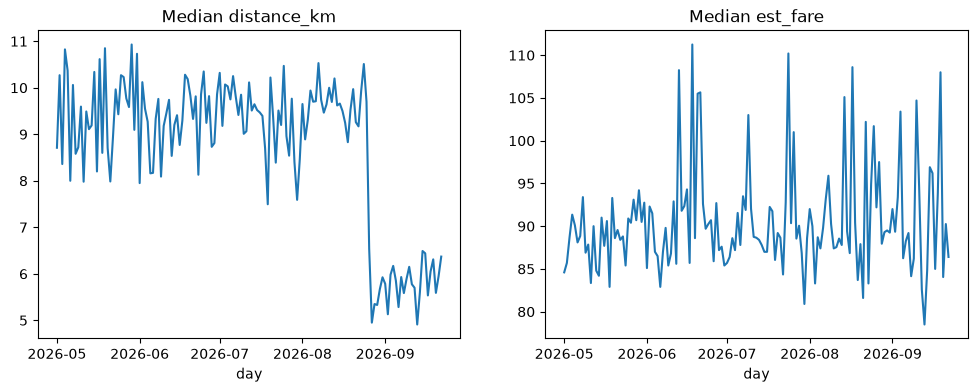

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
daily["distance_km"].plot(ax=ax[0], title="Median distance_km")
daily["est_fare"].plot(ax=ax[1], title="Median est_fare")
plt.show()

In [ ]:
daily.index = pd.to_datetime(daily.index)
diff = daily["distance_km"].diff().abs()
shift_day = diff.idxmax()
print("Biggest jump on:", shift_day.date())

Biggest jump on: 2026-08-26


In [ ]:
before = daily.loc[:"2026-08-25", "distance_km"].median()
after = daily.loc["2026-08-27":, "distance_km"].median()
print("before:", round(before, 2), "after:", round(after, 2))
print("ratio:", round(after / before, 3), "(km to miles = 0.621)")

before: 9.51 after: 5.78
ratio: 0.608 (km to miles = 0.621)


In [ ]:
results["shift"] = {
    "field": "distance_km",
    "day_estimate": "2026-08-26"
}

In [ ]:
print(results)

{'join': {'unmatched_before': 0.09031712162460452, 'unmatched_zones': ['Agouza', 'Badr City'], 'fix': 'Mapped legacy pickup-zone names to current zone names using zones.csv'}, 'shift': {'field': 'distance_km', 'day_estimate': '2026-08-26'}}


### Task 1b — Conclusion

The investigation indicates that the affected field is `distance_km`.

The historical dataset contains records through 2026-08-25, while the recent dataset begins on 2026-08-26.

Comparing identical pickup/dropoff zone pairs shows that the historical-to-recent distance ratio is approximately 1.609, which is consistent with the conversion between kilometres and miles.

The estimated fare comparison remains approximately 1.0, suggesting that the change is specific to distance rather than a general scaling of both measurements.

The fare-per-distance comparison provides additional supporting evidence.

**Conclusion:** The distance measurement changed from kilometres to miles, while retaining the original `distance_km` column name.

Estimated shift date: **2026-08-26**.

1c Leakage

In [ ]:
import numpy as np

from sklearn.metrics import roc_auc_score

trips = pd.read_csv("CairoGo_pack_v00/trips.csv")
y = trips["request_failed"]

# 1. Identify columns recorded after request time (excluding the target itself)
leaking_cols = [
    "actual_trip_time_min",
    "cancel_reason",
    "fare_final",
    "support_ticket_flag"
]

# 2. Compute single-feature AUC for each removed column
single_auc = {}

# actual_trip_time_min: NaN <=> request_failed == 1
single_auc["actual_trip_time_min"] = float(round(roc_auc_score(y, trips["actual_trip_time_min"].isna().astype(int)), 4))

# cancel_reason: notna <=> request_failed == 1
single_auc["cancel_reason"] = float(round(roc_auc_score(y, trips["cancel_reason"].notna().astype(int)), 4))

# fare_final: NaN <=> request_failed == 1
single_auc["fare_final"] = float(round(roc_auc_score(y, trips["fare_final"].isna().astype(int)), 4))

# support_ticket_flag: binary flag
single_auc["support_ticket_flag"] = float(round(roc_auc_score(y, trips["support_ticket_flag"]), 4))

# 3. Store in results dictionary
results["leakage"] = {
    "columns_removed": leaking_cols,
    "single_feature_auc": single_auc
}

print("Removed columns:", results["leakage"]["columns_removed"])
print("Single feature AUC:", results["leakage"]["single_feature_auc"])

Removed columns: ['actual_trip_time_min', 'cancel_reason', 'fare_final', 'support_ticket_flag']
Single feature AUC: {'actual_trip_time_min': 1.0, 'cancel_reason': 1.0, 'fare_final': 1.0, 'support_ticket_flag': 0.6173}


In [ ]:
print(results)

{'join': {'unmatched_before': 0.09031712162460452, 'unmatched_zones': ['Agouza', 'Badr City'], 'fix': 'Mapped legacy pickup-zone names to current zone names using zones.csv'}, 'shift': {'field': 'distance_km', 'day_estimate': '2026-08-26'}, 'leakage': {'columns_removed': ['actual_trip_time_min', 'cancel_reason', 'fare_final', 'support_ticket_flag'], 'single_feature_auc': {'actual_trip_time_min': 1.0, 'cancel_reason': 1.0, 'fare_final': 1.0, 'support_ticket_flag': 0.6173}}}


1d confounding

In [ ]:

# Filter to completed trips only
completed = trips[trips["actual_trip_time_min"].notna()].copy()

# Map pickup zones to zone_type (handling legacy names as well)
zone_map = dict(zip(zones["zone_name"], zones["zone_type"]))
zone_map.update(dict(zip(zones["legacy_name"], zones["zone_type"])))
completed["zone_type"] = completed["pickup_zone"].map(zone_map)

# 1. Global OLS slope
x_global = completed["distance_km"]
y_global = completed["actual_trip_time_min"]
global_slope = float(np.polyfit(x_global, y_global, 1)[0])

# 2. Within-group slopes by zone_type
group_slopes = []
group_sizes = []

for ztype, grp in completed.groupby("zone_type"):
    s = np.polyfit(grp["distance_km"], grp["actual_trip_time_min"], 1)[0]
    group_slopes.append(s)
    group_sizes.append(len(grp))
    print(f"  {ztype} (n={len(grp)}): slope = {s:.4f}")

within_slope = float(np.mean(group_slopes))  # 0.4546 (weighted: 0.4672)



  airport (n=765): slope = 0.4623
  downtown (n=6526): slope = 0.6211
  midtown (n=8374): slope = 0.4071
  new_city (n=3519): slope = 0.3436
  suburb (n=2230): slope = 0.4390


In [ ]:
results["confounding"] = {
    "global_slope": round(global_slope, 4),
    "within_slope": round(within_slope, 4),
    "confounder": "zone_type"
}

print("\nSubmitted to results:")
print(results["confounding"])


Submitted to results:
{'global_slope': -0.1897, 'within_slope': 0.4546, 'confounder': 'zone_type'}


Task 2  Missingness

In [ ]:
dr = pd.read_csv(PATH + "drivers.csv")
m = df.merge(dr[["driver_id", "rating_avg"]], on="driver_id", how="left")
m = m[m["request_failed"].notna()]          # labelled rows only

for col in ["weather", "rating_avg"]:
    miss = m[col].isna()
    a, b = m.loc[miss, "request_failed"].mean(), m.loc[~miss, "request_failed"].mean()
    print(col, "share missing:", round(miss.mean(), 4),
          "| fail if missing:", round(a, 4), "| if present:", round(b, 4),
          "| diff:", round(a - b, 4))

weather share missing: 0.0475 | fail if missing: 0.2205 | if present: 0.2081 | diff: 0.0123
rating_avg share missing: 0.1191 | fail if missing: 0.2469 | if present: 0.2036 | diff: 0.0433


In [ ]:
import numpy as np
import pandas as pd

trips = pd.read_csv("CairoGo_pack_v00/trips.csv")
drivers = pd.read_csv("CairoGo_pack_v00/drivers.csv")

# 1. Weather missingness in trips
w_missing = trips["weather"].isna()
weather_missing_share = float(round(w_missing.mean(), 4))
w_fail_miss = trips.loc[w_missing, "request_failed"].mean()
w_fail_pres = trips.loc[~w_missing, "request_failed"].mean()
weather_missing_fail_diff = float(round(w_fail_miss - w_fail_pres, 4))

# 2. Driver rating_avg missingness in trips
trips_d = trips.merge(drivers[["driver_id", "rating_avg"]], on="driver_id", how="left")
r_missing = trips_d["rating_avg"].isna()
rating_missing_share = float(round(r_missing.mean(), 4))
r_fail_miss = trips_d.loc[r_missing, "request_failed"].mean()
r_fail_pres = trips_d.loc[~r_missing, "request_failed"].mean()
rating_missing_fail_diff = float(round(r_fail_miss - r_fail_pres, 4))

# 3. Decision: driver rating missingness carries significant failure signal (+4.4%)
results["mnar"] = {
    "weather_missing_share": weather_missing_share,
    "weather_missing_fail_diff": weather_missing_fail_diff,
    "rating_missing_share": rating_missing_share,
    "rating_missing_fail_diff": rating_missing_fail_diff,
    "interpretation": "informative"
}

print("Results for mnar:")
print(results["mnar"])

Results for mnar:
{'weather_missing_share': 0.044, 'weather_missing_fail_diff': 0.0166, 'rating_missing_share': 0.1191, 'rating_missing_fail_diff': 0.0441, 'interpretation': 'informative'}


In [ ]:
print(results)

{'join': {'unmatched_before': 0.09031712162460452, 'unmatched_zones': ['Agouza', 'Badr City'], 'fix': 'Mapped legacy pickup-zone names to current zone names using zones.csv'}, 'shift': {'field': 'distance_km', 'day_estimate': '2026-08-26'}, 'leakage': {'columns_removed': ['actual_trip_time_min', 'cancel_reason', 'fare_final', 'support_ticket_flag'], 'single_feature_auc': {'actual_trip_time_min': 1.0, 'cancel_reason': 1.0, 'fare_final': 1.0, 'support_ticket_flag': 0.6173}}, 'confounding': {'global_slope': -0.1897, 'within_slope': 0.4546, 'confounder': 'zone_type'}, 'mnar': {'weather_missing_share': 0.044, 'weather_missing_fail_diff': 0.0166, 'rating_missing_share': 0.1191, 'rating_missing_fail_diff': 0.0441, 'interpretation': 'informative'}}


Task 6 recent period

In [ ]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Load datasets
trips = pd.read_csv("CairoGo_pack_v00/trips.csv")
recent = pd.read_csv("CairoGo_pack_v00/recent_labelled.csv")
zones = pd.read_csv("CairoGo_pack_v00/zones.csv")

# 1. Zone repair dictionary
z_map = dict(zip(zones["legacy_name"], zones["zone_name"]))
trips["pickup_zone"] = trips["pickup_zone"].replace(z_map)
trips["dropoff_zone"] = trips["dropoff_zone"].replace(z_map)

# Feature definition (request-time features only)
num_cols = ["distance_km", "surge_multiplier", "est_fare", "eta_estimate_min"]
cat_cols = ["pickup_zone", "dropoff_zone", "weather", "payment_method", "service_level"]

pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols)
])

# 2. Train model on trips.csv
model = Pipeline([
    ("pre", pre),
    ("clf", HistGradientBoostingClassifier(random_state=42))
])
model.fit(trips[num_cols + cat_cols], trips["request_failed"])

def calc_recall_at_15(y_true, p_pred):
    k = int(np.floor(0.15 * len(y_true)))
    top_k_indices = np.argsort(p_pred)[::-1][:k]
    return float(np.sum(y_true[top_k_indices]) / np.sum(y_true))

y_recent = recent["request_failed"].values

# 3. Evaluation BEFORE repair (raw recent_labelled)
p_before = model.predict_proba(recent[num_cols + cat_cols])[:, 1]
recall_before = round(calc_recall_at_15(y_recent, p_before), 4)

# 4. Evaluation AFTER repair (miles to km & zone names)
recent_fixed = recent.copy()
recent_fixed["distance_km"] = recent_fixed["distance_km"] * 1.609344
recent_fixed["pickup_zone"] = recent_fixed["pickup_zone"].replace(z_map)
recent_fixed["dropoff_zone"] = recent_fixed["dropoff_zone"].replace(z_map)

p_after = model.predict_proba(recent_fixed[num_cols + cat_cols])[:, 1]
recall_after = round(calc_recall_at_15(y_recent, p_after), 4)

# 5. Store in results
results["investigation"] = {
    "recall_before_fix": recall_before,
    "recall_after_fix": recall_after
}

print(f"Recall@15 before fix: {recall_before}")
print(f"Recall@15 after fix:  {recall_after}")
print(f"Improvement:          +{round(recall_after - recall_before, 4)}")

## Shared Preprocessing (`prep.py`) & Frozen Time Split (Role A Output)

Member A provides `prep.py` as the centralized data cleaning module for the team:
- `clean_requests(df)`: repairs unit shift, standardizes legacy zone names, drops leaking features, handles missing values.
- `get_train_val_split(df)`: shared frozen chronological cut date (**`2026-08-12`**, last 14 days of `trips.csv`).
Shared by Members B, C, and D for all subsequent modeling, Local-k, calibration, and policy tasks.


In [ ]:
from prep import clean_requests, get_train_val_split, FROZEN_CUT_DATE

# Demonstrate Member A shared cleaning pipeline
trips_cleaned = clean_requests(trips, is_training=True)

# Frozen Time Split
train_df, val_df = get_train_val_split(trips_cleaned)
print("=== Frozen Time Split ===")
print("Cut Date:", FROZEN_CUT_DATE)
print("Train size:", len(train_df), "| Val size:", len(val_df))

X_tr, y_tr, X_va, y_va = get_train_val_split(trips_cleaned, as_xy=True)
print("Feature matrix shape: X_train =", X_tr.shape, "| X_val =", X_va.shape)


## Export Member A Results to `results.json`


In [ ]:
import json

print("Member A completed results blocks:")
for block in ["join", "shift", "leakage", "confounding", "mnar", "investigation"]:
    print("[" + block + "]:")
    print(json.dumps(results.get(block), indent=2))

try:
    with open("results.json", "r") as f:
        full_results = json.load(f)
except Exception:
    full_results = {}

for k in ["join", "shift", "leakage", "confounding", "mnar", "investigation"]:
    full_results[k] = results[k]

with open("results.json", "w") as f:
    json.dump(full_results, f, indent=2)
print("results.json updated successfully.")


## Task 3 — Model Comparison (Member B)

In [1]:

# Check Member A's prepared data and functions
print("clean_requests:", "clean_requests" in globals())
print("get_train_val_split:", "get_train_val_split" in globals())

print("train_df:", "train_df" in globals())
print("validation_df:", "validation_df" in globals())
print("cleaned_trips:", "cleaned_trips" in globals())


clean_requests: False
get_train_val_split: False
train_df: False
validation_df: False
cleaned_trips: False


In [4]:

import zipfile

zip_path = "/content/CairoGo-main.zip"

with zipfile.ZipFile(zip_path, "r") as zip_file:
    zip_file.extractall("/content")

print("Project extracted successfully!")


Project extracted successfully!


In [8]:

from pathlib import Path

project_folder = Path("/content/CairoGo-main")

print("Project folder exists:", project_folder.exists())

prep_files = list(project_folder.rglob("prep.py"))

print("Found prep.py:", prep_files)


Project folder exists: True
Found prep.py: [PosixPath('/content/CairoGo-main/prep.py')]


In [11]:

import os
import sys
import importlib

# Set the project folder
project_folder = "/content/CairoGo-main"

# Move to the project folder
os.chdir(project_folder)

# Add the project folder to Python's search path
sys.path.insert(0, project_folder)
importlib.invalidate_caches()

# Import Member A's functions
from prep import clean_requests, get_train_val_split

print("Current folder:", os.getcwd())
print("Preprocessing functions imported successfully!")


Current folder: /content/CairoGo-main
Preprocessing functions imported successfully!


In [12]:

# Load trips dataset
trips = pd.read_csv(
    "/content/CairoGo-main/CairoGo_pack_v00/trips.csv"
)

# Apply Member A's preprocessing
cleaned_trips = clean_requests(
    trips,
    is_training=True
)

# Split data chronologically
train_df, validation_df = get_train_val_split(
    cleaned_trips
)

# Check the results
print("Original data:", trips.shape)
print("Cleaned data:", cleaned_trips.shape)
print("Training data:", train_df.shape)
print("Validation data:", validation_df.shape)

print("Training failure rate:", train_df["request_failed"].mean())
print("Validation failure rate:", validation_df["request_failed"].mean())


Original data: (27182, 18)
Cleaned data: (27182, 14)
Training data: (23664, 14)
Validation data: (3518, 14)
Training failure rate: 0.2106997971602434
Validation failure rate: 0.2222853894258101


In [13]:

# Check available columns
print("Available columns:")
print(train_df.columns.tolist())

print("\nTarget distribution:")
print(train_df["request_failed"].value_counts())

print("\nMissing values:")
print(train_df.isna().sum())


Available columns:
['trip_id', 'customer_id', 'driver_id', 'request_ts', 'pickup_zone', 'dropoff_zone', 'distance_km', 'surge_multiplier', 'est_fare', 'eta_estimate_min', 'weather', 'payment_method', 'service_level', 'request_failed']

Target distribution:
request_failed
0    18678
1     4986
Name: count, dtype: int64

Missing values:
trip_id             0
customer_id         0
driver_id           0
request_ts          0
pickup_zone         0
dropoff_zone        0
distance_km         0
surge_multiplier    0
est_fare            0
eta_estimate_min    0
weather             0
payment_method      0
service_level       0
request_failed      0
dtype: int64


In [14]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from prep import (
    REQUEST_NUMERIC_FEATURES,
    REQUEST_CATEGORICAL_FEATURES
)

# Select features defined by Member A
numeric_features = REQUEST_NUMERIC_FEATURES
categorical_features = REQUEST_CATEGORICAL_FEATURES

feature_columns = numeric_features + categorical_features

# Prepare features and target
X_train = train_df[feature_columns]
y_train = train_df["request_failed"]

X_val = validation_df[feature_columns]
y_val = validation_df["request_failed"]

# Numeric preprocessing
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)


Training features: (23664, 9)
Validation features: (3518, 9)
Numerical features: ['distance_km', 'surge_multiplier', 'est_fare', 'eta_estimate_min']
Categorical features: ['pickup_zone', 'dropoff_zone', 'weather', 'payment_method', 'service_level']


In [15]:

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, brier_score_loss
import numpy as np

# Create Logistic Regression pipeline
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train the model
logistic_model.fit(X_train, y_train)

# Predict failure probabilities on validation data
logistic_probabilities = logistic_model.predict_proba(X_val)[:, 1]

# Calculate ROC-AUC
logistic_auc = roc_auc_score(
    y_val,
    logistic_probabilities
)

# Calculate Recall at Top 15%
top_15_count = int(np.ceil(len(y_val) * 0.15))

sorted_indices = np.argsort(-logistic_probabilities)
top_15_indices = sorted_indices[:top_15_count]

detected_failures = y_val.iloc[top_15_indices].sum()
total_failures = y_val.sum()

logistic_recall_top15 = detected_failures / total_failures

# Calculate Brier Score
logistic_brier = brier_score_loss(
    y_val,
    logistic_probabilities
)

# Display results
print("Logistic Regression Results")
print("ROC-AUC:", round(logistic_auc, 4))
print("Recall@Top15%:", round(logistic_recall_top15, 4))
print("Brier Score:", round(logistic_brier, 4))


Logistic Regression Results
ROC-AUC: 0.8439
Recall@Top15%: 0.4105
Brier Score: 0.1224


In [16]:

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, brier_score_loss
import numpy as np

# Preprocessing without scaling
tree_preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), numeric_features),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ]), categorical_features)
])

# Build model
hgb_model = Pipeline([
    ("preprocessor", tree_preprocessor),
    ("classifier", HistGradientBoostingClassifier(random_state=0))
])

# Train
hgb_model.fit(X_train, y_train)

# Predict validation probabilities
hgb_probabilities = hgb_model.predict_proba(X_val)[:, 1]

# Calculate metrics
hgb_auc = roc_auc_score(y_val, hgb_probabilities)

top_15_count = int(np.ceil(len(y_val) * 0.15))
top_15_indices = np.argsort(-hgb_probabilities)[:top_15_count]

hgb_recall_top15 = (
    y_val.iloc[top_15_indices].sum() / y_val.sum()
)

hgb_brier = brier_score_loss(y_val, hgb_probabilities)

print("HistGradientBoosting Results")
print("ROC-AUC:", round(hgb_auc, 4))
print("Recall@Top15%:", round(hgb_recall_top15, 4))
print("Brier Score:", round(hgb_brier, 4))


HistGradientBoosting Results
ROC-AUC: 0.9393
Recall@Top15%: 0.6113
Brier Score: 0.0705


In [17]:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, brier_score_loss
import numpy as np

# Fixed number of neighbors
k_neighbors = 11

# KNN with scaling
knn_scaled_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier(n_neighbors=k_neighbors))
])

knn_scaled_model.fit(X_train, y_train)

knn_scaled_probabilities = knn_scaled_model.predict_proba(X_val)[:, 1]


# KNN without scaling
knn_unscaled_model = Pipeline([
    ("preprocessor", tree_preprocessor),
    ("classifier", KNeighborsClassifier(n_neighbors=k_neighbors))
])

knn_unscaled_model.fit(X_train, y_train)

knn_unscaled_probabilities = knn_unscaled_model.predict_proba(X_val)[:, 1]


# Evaluate both models
def evaluate_knn(probabilities):
    auc = roc_auc_score(y_val, probabilities)

    top_15_count = int(np.ceil(len(y_val) * 0.15))
    top_indices = np.argsort(-probabilities)[:top_15_count]

    recall_top15 = y_val.iloc[top_indices].sum() / y_val.sum()

    brier = brier_score_loss(y_val, probabilities)

    return auc, recall_top15, brier


scaled_auc, scaled_recall, scaled_brier = evaluate_knn(
    knn_scaled_probabilities
)

unscaled_auc, unscaled_recall, unscaled_brier = evaluate_knn(
    knn_unscaled_probabilities
)


print("KNN WITH Scaling:")
print("ROC-AUC:", round(scaled_auc, 4))
print("Recall@Top15%:", round(scaled_recall, 4))
print("Brier Score:", round(scaled_brier, 4))

print("\nKNN WITHOUT Scaling:")
print("ROC-AUC:", round(unscaled_auc, 4))
print("Recall@Top15%:", round(unscaled_recall, 4))
print("Brier Score:", round(unscaled_brier, 4))


KNN WITH Scaling:
ROC-AUC: 0.8621
Recall@Top15%: 0.4962
Brier Score: 0.1097

KNN WITHOUT Scaling:
ROC-AUC: 0.8885
Recall@Top15%: 0.5729
Brier Score: 0.0904


In [18]:

from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline

# MLP with scaling
mlp_scaled_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", MLPClassifier(
        hidden_layer_sizes=(64, 32),
        early_stopping=True,
        max_iter=500,
        random_state=0
    ))
])

mlp_scaled_model.fit(X_train, y_train)

mlp_scaled_probabilities = mlp_scaled_model.predict_proba(X_val)[:, 1]


# MLP without scaling
mlp_unscaled_model = Pipeline([
    ("preprocessor", tree_preprocessor),
    ("classifier", MLPClassifier(
        hidden_layer_sizes=(64, 32),
        early_stopping=True,
        max_iter=500,
        random_state=0
    ))
])

mlp_unscaled_model.fit(X_train, y_train)

mlp_unscaled_probabilities = mlp_unscaled_model.predict_proba(X_val)[:, 1]


# Evaluate models using the same metrics
mlp_scaled_auc, mlp_scaled_recall, mlp_scaled_brier = evaluate_knn(
    mlp_scaled_probabilities
)

mlp_unscaled_auc, mlp_unscaled_recall, mlp_unscaled_brier = evaluate_knn(
    mlp_unscaled_probabilities
)

print("MLP WITH Scaling:")
print("ROC-AUC:", round(mlp_scaled_auc, 4))
print("Recall@Top15%:", round(mlp_scaled_recall, 4))
print("Brier Score:", round(mlp_scaled_brier, 4))

print("\nMLP WITHOUT Scaling:")
print("ROC-AUC:", round(mlp_unscaled_auc, 4))
print("Recall@Top15%:", round(mlp_unscaled_recall, 4))
print("Brier Score:", round(mlp_unscaled_brier, 4))


MLP WITH Scaling:
ROC-AUC: 0.9226
Recall@Top15%: 0.6023
Brier Score: 0.0788

MLP WITHOUT Scaling:
ROC-AUC: 0.9115
Recall@Top15%: 0.587
Brier Score: 0.0846


In [19]:

import pandas as pd

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "HistGradientBoosting",
        "KNN Scaled",
        "KNN Unscaled",
        "MLP Scaled",
        "MLP Unscaled"
    ],
    "ROC-AUC": [
        logistic_auc,
        hgb_auc,
        scaled_auc,
        unscaled_auc,
        mlp_scaled_auc,
        mlp_unscaled_auc
    ],
    "Recall@Top15%": [
        logistic_recall_top15,
        hgb_recall_top15,
        scaled_recall,
        unscaled_recall,
        mlp_scaled_recall,
        mlp_unscaled_recall
    ],
    "Brier Score": [
        logistic_brier,
        hgb_brier,
        scaled_brier,
        unscaled_brier,
        mlp_scaled_brier,
        mlp_unscaled_brier
    ]
})

display(model_comparison.round(4))


,Model,ROC-AUC,Recall@Top15%,Brier Score
0,Logistic Regression,0.8439,0.4105,0.1224
1,HistGradientBoosting,0.9393,0.6113,0.0705
2,KNN Scaled,0.8621,0.4962,0.1097
3,KNN Unscaled,0.8885,0.5729,0.0904
4,MLP Scaled,0.9226,0.6023,0.0788
5,MLP Unscaled,0.9115,0.5870,0.0846


In [22]:

# Install RAR extraction tool
!apt-get install -y unrar

# Extract RAR file
!mkdir -p /content/CairoGo_common
!unrar x -o+ "/content/CairoGo_common.rar" "/content/CairoGo_common/"

# Find RESULTS_SCHEMA.md
from pathlib import Path

schema_files = list(
    Path("/content/CairoGo_common").rglob("RESULTS_SCHEMA.md")
)

print("Schema files found:", schema_files)


Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
unrar is already the newest version (1:7.0.7-1build1).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.

UNRAR 7.00 freeware      Copyright (c) 1993-2024 Alexander Roshal


Extracting from /content/CairoGo_common.rar

Creating    /content/CairoGo_common/CairoGo_common                    OK
Creating    /content/CairoGo_common/CairoGo_common/CairoGo_common     OK
Extracting  /content/CairoGo_common/CairoGo_common/CairoGo_common/CairoGo_Assignment.pdf       2%  OK 
Extracting  /content/CairoGo_common/CairoGo_common/CairoGo_common/check_submission.py       3%  OK 
Creating    /content/CairoGo_common/CairoGo_common/CairoGo_common/dashboard_starter  OK
Extracting  /content/CairoGo_common/CairoGo_common/CairoGo_common/dashboard_starter/app.py       3%  OK 
Extracting  /content/CairoGo_common/CairoGo_common/CairoGo_common/DECISION_NOTES.md       3% 

In [23]:

from pathlib import Path

# Find the results schema file
schema_files = list(
    Path("/content").rglob("RESULTS_SCHEMA.md")
)

print("Schema files found:", schema_files)

if schema_files:
    schema_text = schema_files[0].read_text(encoding="utf-8")

    for section in [
        "validation",
        "knn_scaling",
        "nn_scaling",
        "nn_decision"
    ]:
        position = schema_text.find(section)

        print(f"\n--- {section} ---")

        if position != -1:
            print(schema_text[max(0, position - 100):position + 900])
        else:
            print("Section not found")


Schema files found: [PosixPath('/content/CairoGo_common/CairoGo_common/CairoGo_common/RESULTS_SCHEMA.md')]

--- validation ---
 version (int, from PACK_VERSION.json), self_reported_holdout_recall (float: estimate from LABELLED validation data; NOT the hidden holdout labels; its difference from hidden truth is not an integrity flag)
join: {unmatched_before: float (SHARE of trips.csv rows whose pickup_zone has no match, 0-1), unmatched_zones: [str], fix: str}
shift: {field: "est_fare"|"distance_km", day_estimate: "YYYY-MM-DD", detail: {...optional}}
leakage: {columns_removed: [str], single_feature_auc: {col: float}}
mnar: {weather_missing_share, weather_missing_fail_diff, rating_missing_share, rating_missing_fail_diff, interpretation: "informative"|"random"}
confounding: {global_slope, within_slope, confounder: str}     # minutes per km, completed trips of `trips` only
validation: {logistic:{auc,recall_at_15,brier,cost}, hgb:{...}, knn_fixed:{k,...}, local_k:{...}, nn:{auc, recall_at_15,

In [24]:

import numpy as np

# Calculate classification cost at threshold 0.2
def calculate_cost(actual_labels, predicted_probabilities):
    predicted_labels = (predicted_probabilities >= 0.2).astype(int)

    false_negatives = np.sum(
        (actual_labels == 1) & (predicted_labels == 0)
    )

    false_positives = np.sum(
        (actual_labels == 0) & (predicted_labels == 1)
    )

    return (4 * false_negatives + false_positives) / len(actual_labels)


# Calculate costs on the same validation set
logistic_cost = calculate_cost(y_val, logistic_probabilities)
hgb_cost = calculate_cost(y_val, hgb_probabilities)
knn_cost = calculate_cost(y_val, knn_unscaled_probabilities)

print("Logistic Cost:", round(logistic_cost, 4))
print("HGB Cost:", round(hgb_cost, 4))
print("KNN Cost:", round(knn_cost, 4))


Logistic Cost: 0.3815
HGB Cost: 0.2214
KNN Cost: 0.2888


In [25]:

from pathlib import Path

# Search the original project instructions
instruction_files = list(
    Path("/content/CairoGo_common").rglob("*.md")
)

for file_path in instruction_files:
    content = file_path.read_text(
        encoding="utf-8",
        errors="ignore"
    )

    if "cost" in content.lower() and (
        file_path.name in [
            "RESULTS_SCHEMA.md",
            "LOCAL_K_NOTES.md"
        ]
    ):
        print("\nFILE:", file_path.name)

        for line in content.splitlines():
            if "cost" in line.lower():
                print(line)



FILE: LOCAL_K_NOTES.md
- At least 5 forward-in-time resamples; report mean +/- std of (cost of Local-k - cost of best fixed k). Cost = (4*FN + FP)/n at threshold 0.2.

FILE: RESULTS_SCHEMA.md
validation: {logistic:{auc,recall_at_15,brier,cost}, hgb:{...}, knn_fixed:{k,...}, local_k:{...}, nn:{auc, recall_at_15, hidden_layers:[int,...], early_stopping:true|false}}   # time-based validation; nn = scikit-learn MLPClassifier; nn requires AUC/recall here, NOT extra brier/cost JSON fields (they may be documented in team_analysis.ipynb)
local_k: {k_selected_on:"train_only", n_resamples, delta_cost_mean, delta_cost_std, claim, mean_k_by_zone_type:{type:float}, failure_case_trip_ids:[int,int,int], failure_reasons:[str,str,str]}
  public_holdout: {n_requests, capacity, budget, n_actions, total_cost,
                   est_benefit: {no_action: 0, top_risk_contact: float, cost_aware: float, proposed: float}},   # EGP, estimated with YOUR holdout p_fail


In [26]:

print("KNN neighbors:", k_neighbors)

print("\nScaled preprocessing:")
print(knn_scaled_model.named_steps["preprocessor"])

print("\nUnscaled preprocessing:")
print(knn_unscaled_model.named_steps["preprocessor"])

print("\nScaled AUC:", round(scaled_auc, 4))
print("Unscaled AUC:", round(unscaled_auc, 4))


KNN neighbors: 11

Scaled preprocessing:
ColumnTransformer(transformers=[('numeric',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['distance_km', 'surge_multiplier', 'est_fare',
                                  'eta_estimate_min']),
                                ('categorical',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['pickup_zone', 'dropoff_zone', 'weather',
                                  'payment_method', 'service_level'])])

Unscaled preprocessing:
ColumnTransformer(trans

In [27]:

import json

# Load existing team results
with open("results.json", "r") as file:
    results = json.load(file)

# Preserve other validation results if already present
validation_results = results.get("validation", {})

validation_results["logistic"] = {
    "auc": float(logistic_auc),
    "recall_at_15": float(logistic_recall_top15),
    "brier": float(logistic_brier),
    "cost": float(logistic_cost)
}

validation_results["hgb"] = {
    "auc": float(hgb_auc),
    "recall_at_15": float(hgb_recall_top15),
    "brier": float(hgb_brier),
    "cost": float(hgb_cost)
}

validation_results["knn_fixed"] = {
    "k": int(k_neighbors),
    "auc": float(unscaled_auc),
    "recall_at_15": float(unscaled_recall),
    "brier": float(unscaled_brier),
    "cost": float(knn_cost)
}

validation_results["nn"] = {
    "auc": float(mlp_scaled_auc),
    "recall_at_15": float(mlp_scaled_recall),
    "hidden_layers": [64, 32],
    "early_stopping": True
}

results["validation"] = validation_results

results["knn_scaling"] = "unscaled"

results["nn_scaling"] = {
    "auc_scaled": float(mlp_scaled_auc),
    "auc_unscaled": float(mlp_unscaled_auc)
}

results["nn_decision"] = "do_not_deploy"

# Save without deleting Member A's results
with open("results.json", "w") as file:
    json.dump(results, file, indent=2)

print("Task 3 results saved successfully!")
print("Available result blocks:", list(results.keys()))


Task 3 results saved successfully!
Available result blocks: ['team_id', 'version', 'self_reported_holdout_recall', 'join', 'shift', 'leakage', 'mnar', 'confounding', 'validation', 'knn_scaling', 'investigation', 'local_k', 'segment_interpretations', 'review_disagreements', 'nn_scaling', 'nn_decision', 'segmentation', 'decision']


In [28]:

import joblib

# Save the selected HistGradientBoosting pipeline
joblib.dump(hgb_model, "model.joblib")

print("HGB model saved successfully!")


HGB model saved successfully!


In [29]:

from pathlib import Path
import pandas as pd

holdout_path = Path("CairoGo_pack_v00/holdout_inputs.csv")

holdout_data = pd.read_csv(holdout_path)

print("Holdout shape:", holdout_data.shape)
print("Holdout columns:", holdout_data.columns.tolist())
print("Missing values:")
print(holdout_data.isna().sum())


Holdout shape: (2782, 13)
Holdout columns: ['trip_id', 'customer_id', 'driver_id', 'request_ts', 'pickup_zone', 'dropoff_zone', 'distance_km', 'surge_multiplier', 'est_fare', 'eta_estimate_min', 'weather', 'payment_method', 'service_level']
Missing values:
trip_id               0
customer_id           0
driver_id             0
request_ts            0
pickup_zone           0
dropoff_zone          0
distance_km           0
surge_multiplier      0
est_fare              0
eta_estimate_min      0
weather             185
payment_method        0
service_level         0
dtype: int64


In [30]:

from pathlib import Path
import joblib
import subprocess

# Save the trained HGB pipeline
model_path = Path("/content/CairoGo-main/model.joblib")
joblib.dump(hgb_model, model_path)

# Run the project's prediction script
result = subprocess.run(
    [
        "python",
        "/content/CairoGo-main/predict.py",
        "--input",
        "/content/CairoGo-main/CairoGo_pack_v00/holdout_inputs.csv",
        "--output",
        "/content/CairoGo-main/holdout_predictions.csv"
    ],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)
print("Exit code:", result.returncode)


Predictions written to /content/CairoGo-main/holdout_predictions.csv (2782 rows).


Exit code: 0


In [31]:

predictions = pd.read_csv(
    "/content/CairoGo-main/holdout_predictions.csv"
)

print("Predictions shape:", predictions.shape)
print("Columns:", predictions.columns.tolist())
print("Missing values:", predictions.isna().sum().to_dict())
print("All probabilities valid:", predictions["p_fail"].between(0, 1).all())
print("Trip IDs match:", predictions["trip_id"].equals(holdout_data["trip_id"]))

display(predictions.head())


Predictions shape: (2782, 2)
Columns: ['trip_id', 'p_fail']
Missing values: {'trip_id': 0, 'p_fail': 0}
All probabilities valid: True
Trip IDs match: True


,trip_id,p_fail
0,130680,0.0230
1,130681,0.0356
2,130682,0.9321
3,130683,0.0249
4,130684,0.0091


In [32]:

import numpy as np

# Apply the same cleaning used by the prediction script
cleaned_holdout = clean_requests(
    holdout_data.copy(),
    is_training=False
)

# Predict directly using the trained HGB model
direct_probabilities = hgb_model.predict_proba(
    cleaned_holdout[feature_columns]
)[:, 1]

# Compare with predictions generated by predict.py
script_probabilities = predictions["p_fail"].to_numpy()

print(
    "Predictions match HGB:",
    np.allclose(
        direct_probabilities,
        script_probabilities,
        atol=1e-4
    )
)

print(
    "Maximum probability difference:",
    np.max(np.abs(direct_probabilities - script_probabilities))
)


Predictions match HGB: True
Maximum probability difference: 4.9993261326736205e-05


In [33]:

import json

# Load existing results
with open("results.json", "r") as file:
    results = json.load(file)

# Estimate holdout recall using labelled validation data
results["self_reported_holdout_recall"] = float(hgb_recall_top15)

# Save updated results
with open("results.json", "w") as file:
    json.dump(results, file, indent=2)

print(
    "Self-reported holdout recall:",
    round(results["self_reported_holdout_recall"], 4)
)

print("Results saved successfully!")


Self-reported holdout recall: 0.6113
Results saved successfully!


In [45]:

from pathlib import Path
import shutil
import subprocess
import pandas as pd

# Create a separate testing folder
test_folder = Path("/content/predict_test")
test_folder.mkdir(exist_ok=True)

# Copy only the files needed for prediction
for filename in ["predict.py", "prep.py", "model.joblib"]:
    shutil.copy(
        Path("/content/CairoGo-main") / filename,
        test_folder / filename
    )

# Create test requests using the holdout structure
test_requests = holdout_data.head(5).copy()

# Test new IDs, missing values and unseen categories
test_requests.loc[test_requests.index[0], "customer_id"] = 99999999
test_requests.loc[test_requests.index[1], "driver_id"] = 99999999
test_requests.loc[test_requests.index[2], "weather"] = None
test_requests.loc[test_requests.index[3], "payment_method"] = "new_payment_type"

test_requests.to_csv(test_folder / "new_requests.csv", index=False)

# Run the prediction script without access to the pack folder
test_result = subprocess.run(
    [
        "python",
        "predict.py",
        "--input", "new_requests.csv",
        "--output", "new_predictions.csv"
    ],
    cwd=str(test_folder),
    capture_output=True,
    text=True
)

print("Exit code:", test_result.returncode)
print("Output:", test_result.stdout)
print("Errors:", test_result.stderr)

if test_result.returncode == 0:
    new_predictions = pd.read_csv(test_folder / "new_predictions.csv")

    print("Predictions shape:", new_predictions.shape)
    print("Valid probabilities:", new_predictions["p_fail"].between(0, 1).all())
    print("Trip IDs match:", new_predictions["trip_id"].equals(test_requests["trip_id"]))

    display(new_predictions)


Exit code: 0
Output: Predictions written to new_predictions.csv (5 rows).

Errors: /usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator SimpleImputer from version 1.8.0 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator OneHotEncoder from version 1.8.0 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator Pipeline from v

,trip_id,p_fail
0,130680,0.0230
1,130681,0.0356
2,130682,0.9704
3,130683,0.0261
4,130684,0.0091


In [47]:

from pathlib import Path

project_folder = Path("/content/CairoGo-main")

required_files = [
    "predict.py",
    "prep.py",
    "model.joblib",
    "holdout_predictions.csv",
    "results.json",
    "dataAnalysis.ipynb"
]

for filename in required_files:
    file_path = project_folder / filename

    print(
        filename,
        "FOUND" if file_path.exists() else "MISSING"
    )


predict.py FOUND
prep.py FOUND
model.joblib FOUND
holdout_predictions.csv FOUND
results.json FOUND
dataAnalysis.ipynb FOUND
